<a href="https://colab.research.google.com/github/Venkatesh-Maloth/Customer-Churn-Prediction/blob/main/data_set_B_venky_vaccine_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H1N1 Vaccine Allocation: Minimising Town Cost (Dataset B)

**Goal:** predict whether each respondent will accept the H1N1 vaccine (`h1n1_vaccine`), then use those predictions to minimise the total money the town spends:

**Total cost = vaccine costs ($500 each) + hospitalisation costs ($25,000 each)**

**Rules from the brief**
- Everyone gets infected (100% infection probability).
- Anyone who wants a vaccine must get one. If we didn't send one, the town pays them $500 instead.
- Vaccines are posted to homes and ruined if unused, so we must predict exactly *who* will accept.
- Hospitalisation probability depends on personal risk factors and vaccination status.

**Outline:** 1. Setup → 2. EDA → 3. Preprocessing → 4. Cost function → 5. Baseline models → 6. Hyperparameter tuning → 7. Threshold optimisation → 8. Submission

## 1. Setup
Import libraries and fix a random seed so results are reproducible.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

### 1.1 Load the data
Upload `dataset_B_training.csv` and `dataset_B_testing.csv` when prompted. If they are already in the Colab folder, the upload step is skipped.

In [ ]:
TRAIN_FILE = 'dataset_B_training.csv'
TEST_FILE = 'dataset_B_testing.csv'

# Ask for an upload only if the files aren't already in the Colab working directory
if not (os.path.exists(TRAIN_FILE) and os.path.exists(TEST_FILE)):
    from google.colab import files
    files.upload()

train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)

print('Training set:', train.shape)
print('Testing set: ', test.shape)
train.head()

Training set: (4756, 31)
Testing set:  (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,4.0,4.0,1.0,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,3.0,1.0,2.0,18 - 34 Years,Some College,White,Female,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,4.0,2.0,45 - 54 Years,College Graduate,White,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,1.0,4.0,18 - 34 Years,College Graduate,White,Female,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,2.0,2.0,1.0,18 - 34 Years,< 12 Years,White,Female,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


### 1.2 Feature groups
The features fall into three groups that need different preprocessing:
- **Ordinal / count:** concern (0–3), knowledge (0–2), opinions (1–5), household sizes, number of chronic conditions
- **Binary:** behaviours, doctor recommendation, health worker, insurance (0 = No, 1 = Yes)
- **Categorical text:** age group, education, race, sex, income, etc.

In [ ]:
TARGET = 'h1n1_vaccine'
ID_COL = 'respondent_id'

ORDINAL = ['h1n1_concern', 'h1n1_knowledge', 'opinion_h1n1_vacc_effective',
           'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc',
           'household_adults', 'household_children', 'number_chronic_med_conditions']

BINARY = ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
          'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
          'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months',
          'health_worker', 'health_insurance']

CATEGORICAL = ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status',
               'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

FEATURES = ORDINAL + BINARY + CATEGORICAL
print(f'{len(ORDINAL)} ordinal + {len(BINARY)} binary + {len(CATEGORICAL)} categorical = {len(FEATURES)} features')

# Check that train and test have the same feature columns
missing_in_test = set(FEATURES) - set(test.columns)
print('Features missing from test set:', missing_in_test if missing_in_test else 'none')

train[FEATURES].info()

8 ordinal + 11 binary + 10 categorical = 29 features
Features missing from test set: none
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   h1n1_concern                   4741 non-null   float64
 1   h1n1_knowledge                 4734 non-null   float64
 2   opinion_h1n1_vacc_effective    4687 non-null   float64
 3   opinion_h1n1_risk              4692 non-null   float64
 4   opinion_h1n1_sick_from_vacc    4692 non-null   float64
 5   household_adults               4722 non-null   float64
 6   household_children             4722 non-null   float64
 7   number_chronic_med_conditions  4756 non-null   int64  
 8   behavioral_antiviral_meds      4739 non-null   float64
 9   behavioral_avoidance           4729 non-null   float64
 10  behavioral_face_mask           4752 non-null   float64
 11  behavioral_wash_ha

## 2. Exploratory Data Analysis (EDA)

### 2.1 Target balance
How many respondents accepted the vaccine? If the classes are imbalanced, accuracy alone would be misleading, so we use ROC-AUC to judge models and **dollar cost** for the final decision.

h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Proportion vaccinated: 0.394


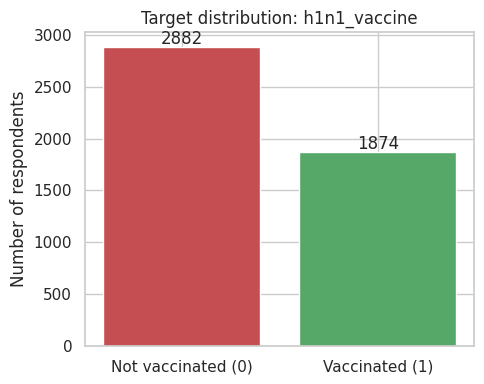

In [ ]:
counts = train[TARGET].value_counts().sort_index()
print(counts)
print('\nProportion vaccinated:', round(train[TARGET].mean(), 3))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Not vaccinated (0)', 'Vaccinated (1)'], counts.values, color=['#C44E52', '#55A868'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, str(v), ha='center')
ax.set_ylabel('Number of respondents')
ax.set_title('Target distribution: h1n1_vaccine')
plt.tight_layout()
plt.show()

### 2.2 Missing values
Some features have large gaps. We also check whether *being missing* is linked to vaccination. If it is, it's better to keep "missing" as its own category than to fill it with a guess.

employment_sector              49.7
health_insurance               40.5
income_poverty                 15.0
doctor_recc_h1n1                6.7
rent_or_own                     6.6
employment_status               4.9
marital_status                  4.8
education                       4.7
child_under_6_months            2.8
health_worker                   2.8
opinion_h1n1_vacc_effective     1.5
opinion_h1n1_sick_from_vacc     1.3
opinion_h1n1_risk               1.3
household_adults                0.7
household_children              0.7
behavioral_avoidance            0.6
h1n1_knowledge                  0.5
behavioral_touch_face           0.4
behavioral_antiviral_meds       0.4
h1n1_concern                    0.3
behavioral_outside_home         0.3
behavioral_large_gatherings     0.2
behavioral_wash_hands           0.2
behavioral_face_mask            0.1


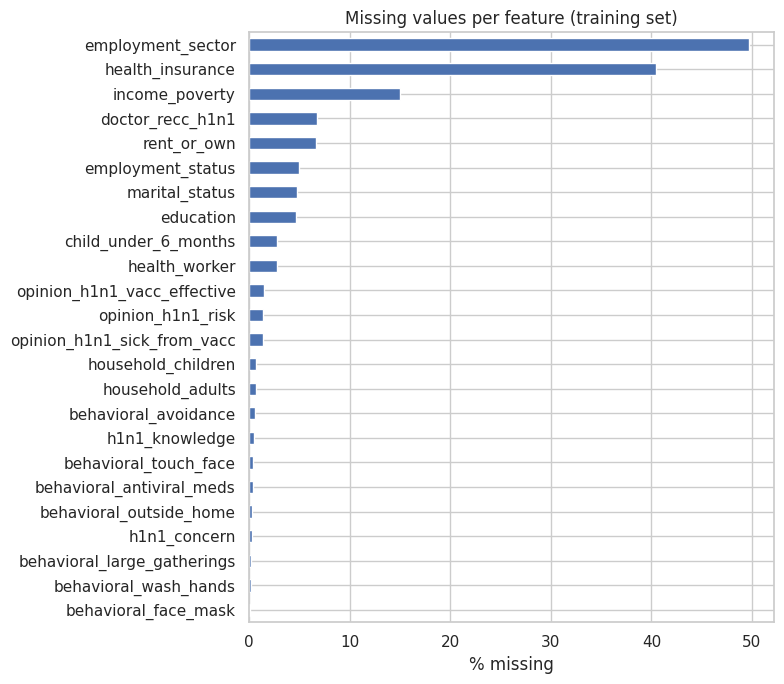


Vaccination rate when value is missing vs present:
health_insurance       missing: 0.24   present: 0.50
employment_sector      missing: 0.38   present: 0.40
income_poverty         missing: 0.37   present: 0.40
doctor_recc_h1n1       missing: 0.18   present: 0.41


In [ ]:
missing = (train[FEATURES].isnull().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
print(missing.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 7))
missing.sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_xlabel('% missing')
ax.set_title('Missing values per feature (training set)')
plt.tight_layout()
plt.show()

# Is missingness informative? Compare vaccination rates for missing vs present values
print('\nVaccination rate when value is missing vs present:')
for col in ['health_insurance', 'employment_sector', 'income_poverty', 'doctor_recc_h1n1']:
    rate_missing = train.loc[train[col].isnull(), TARGET].mean()
    rate_present = train.loc[train[col].notnull(), TARGET].mean()
    print(f'{col:22s} missing: {rate_missing:.2f}   present: {rate_present:.2f}')

### 2.3 Vaccination rate by ordinal and binary features
For each level of each feature, we plot the share of people who got vaccinated. The red dashed line is the overall rate, so bars well above or below it point to strong predictors.

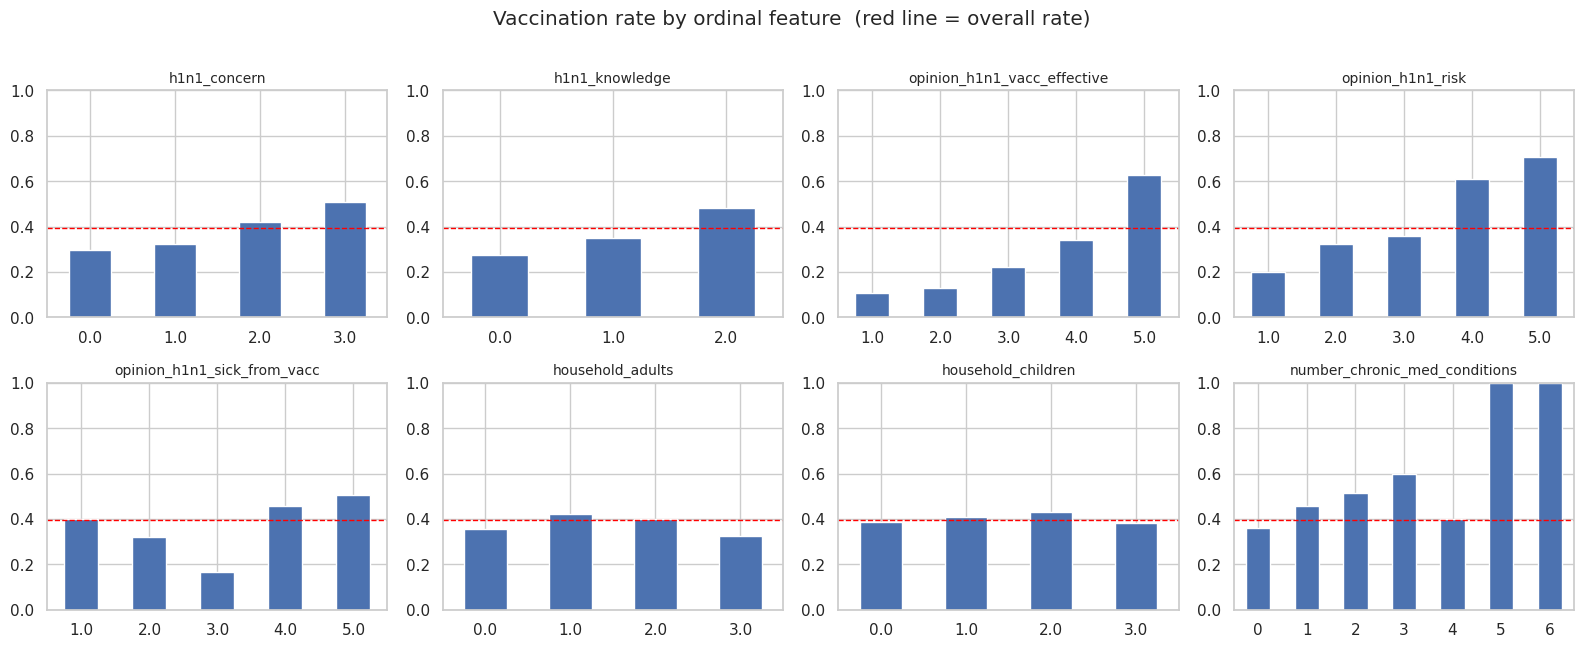

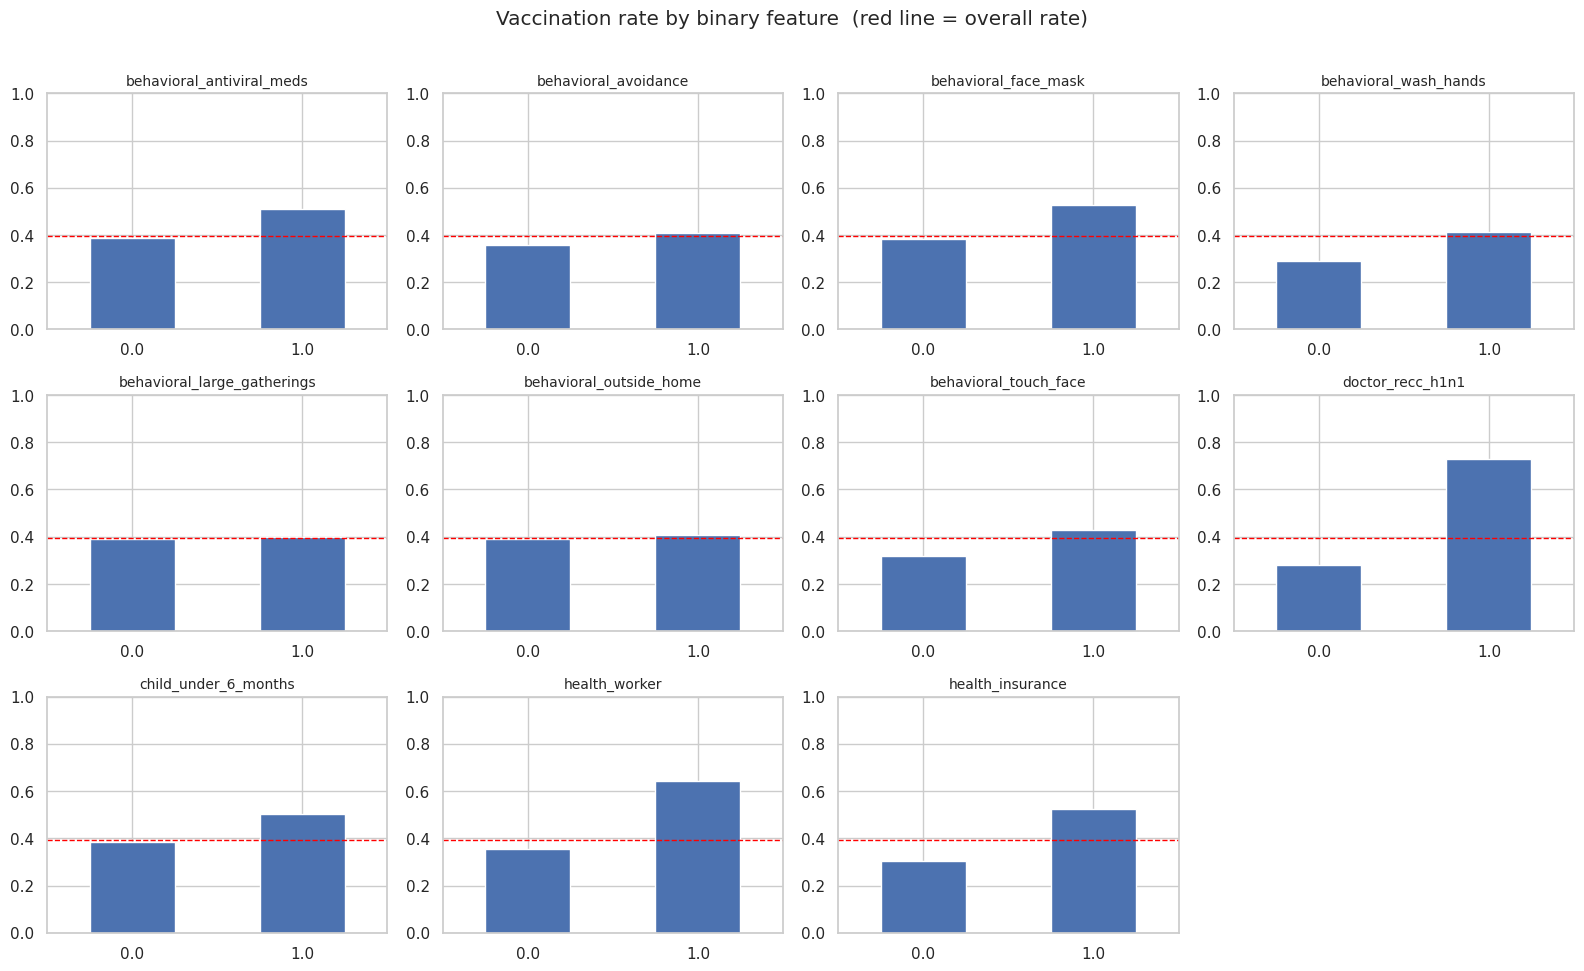

In [ ]:
def plot_rate_by_feature(df, cols, ncols=4, title=''):
    """Bar chart of the vaccination rate (mean of target) for each level of each feature."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = axes.flatten()
    for ax, col in zip(axes, cols):
        rate = df.groupby(col)[TARGET].mean()
        rate.plot(kind='bar', ax=ax, color='#4C72B0')
        ax.axhline(df[TARGET].mean(), color='red', linestyle='--', linewidth=1)
        ax.set_title(col, fontsize=10)
        ax.set_ylim(0, 1)
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=0)
    for ax in axes[len(cols):]:      # hide unused subplots
        ax.set_visible(False)
    fig.suptitle(title + '  (red line = overall rate)', y=1.01)
    plt.tight_layout()
    plt.show()

plot_rate_by_feature(train, ORDINAL, title='Vaccination rate by ordinal feature')
plot_rate_by_feature(train, BINARY, title='Vaccination rate by binary feature')

### 2.4 Vaccination rate by demographic features

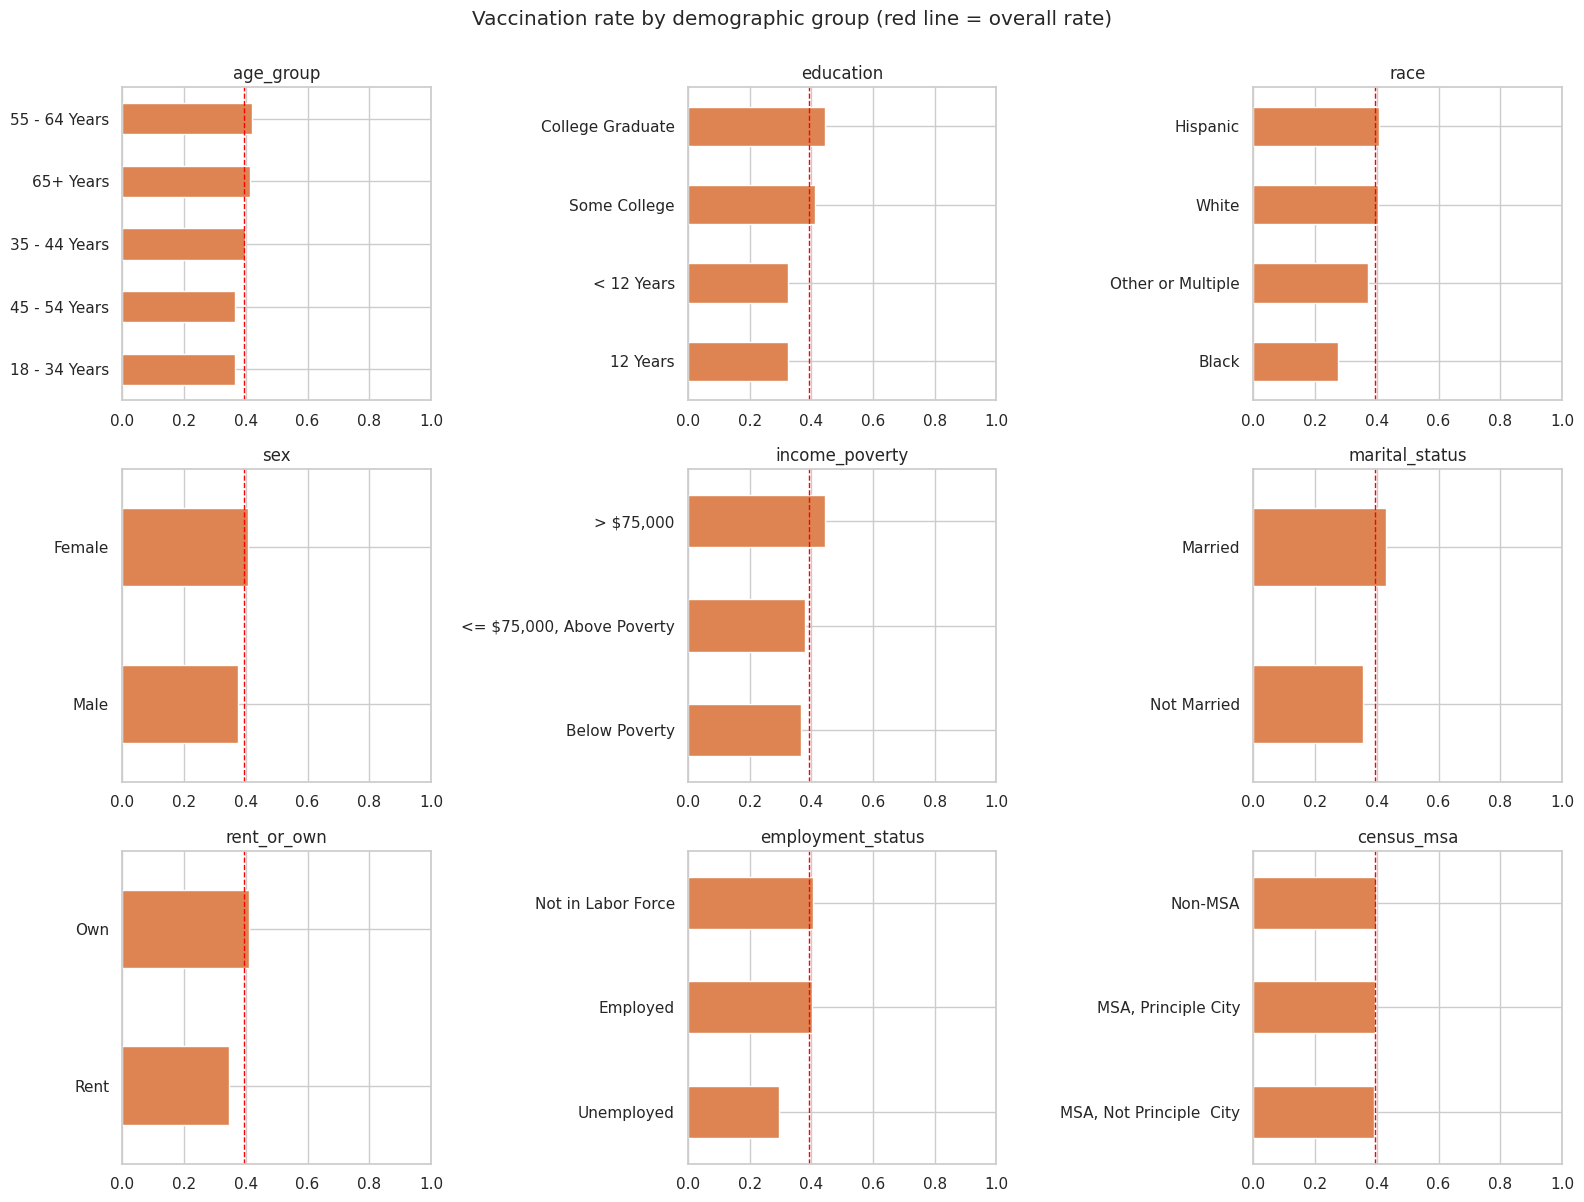

                   mean  count
employment_sector             
technology         0.76     34
healthcare         0.64    546
administrative     0.50     14
science            0.44    320
education          0.44    179
missing            0.38   2364
government         0.38     55
hospitality        0.37     84
wholesale          0.34    211
entertainment      0.30     37
mining             0.29     86
real_estate        0.28     88
manufacturing      0.28     50
media              0.27     11
finance            0.27     96
agriculture        0.26    162
retail             0.25     36
construction       0.25    168
services           0.24     42
transportation     0.21     52
utilities          0.20    120
energy             0.00      1


In [ ]:
demo_cols = [c for c in CATEGORICAL if c != 'employment_sector']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flatten(), demo_cols):
    rate = train.groupby(col)[TARGET].mean().sort_values()
    rate.plot(kind='barh', ax=ax, color='#DD8452')
    ax.axvline(train[TARGET].mean(), color='red', linestyle='--', linewidth=1)
    ax.set_title(col)
    ax.set_xlim(0, 1)
    ax.set_ylabel('')
plt.suptitle('Vaccination rate by demographic group (red line = overall rate)', y=1.0)
plt.tight_layout()
plt.show()

# Employment sector has many levels, so a table is easier to read
sector_rate = (train.assign(employment_sector=train['employment_sector'].fillna('missing'))
               .groupby('employment_sector')[TARGET].agg(['mean', 'count'])
               .sort_values('mean', ascending=False))
print(sector_rate.round(2).to_string())

### 2.5 Correlations
Checks for redundant numeric features and for their linear relationship with the target.

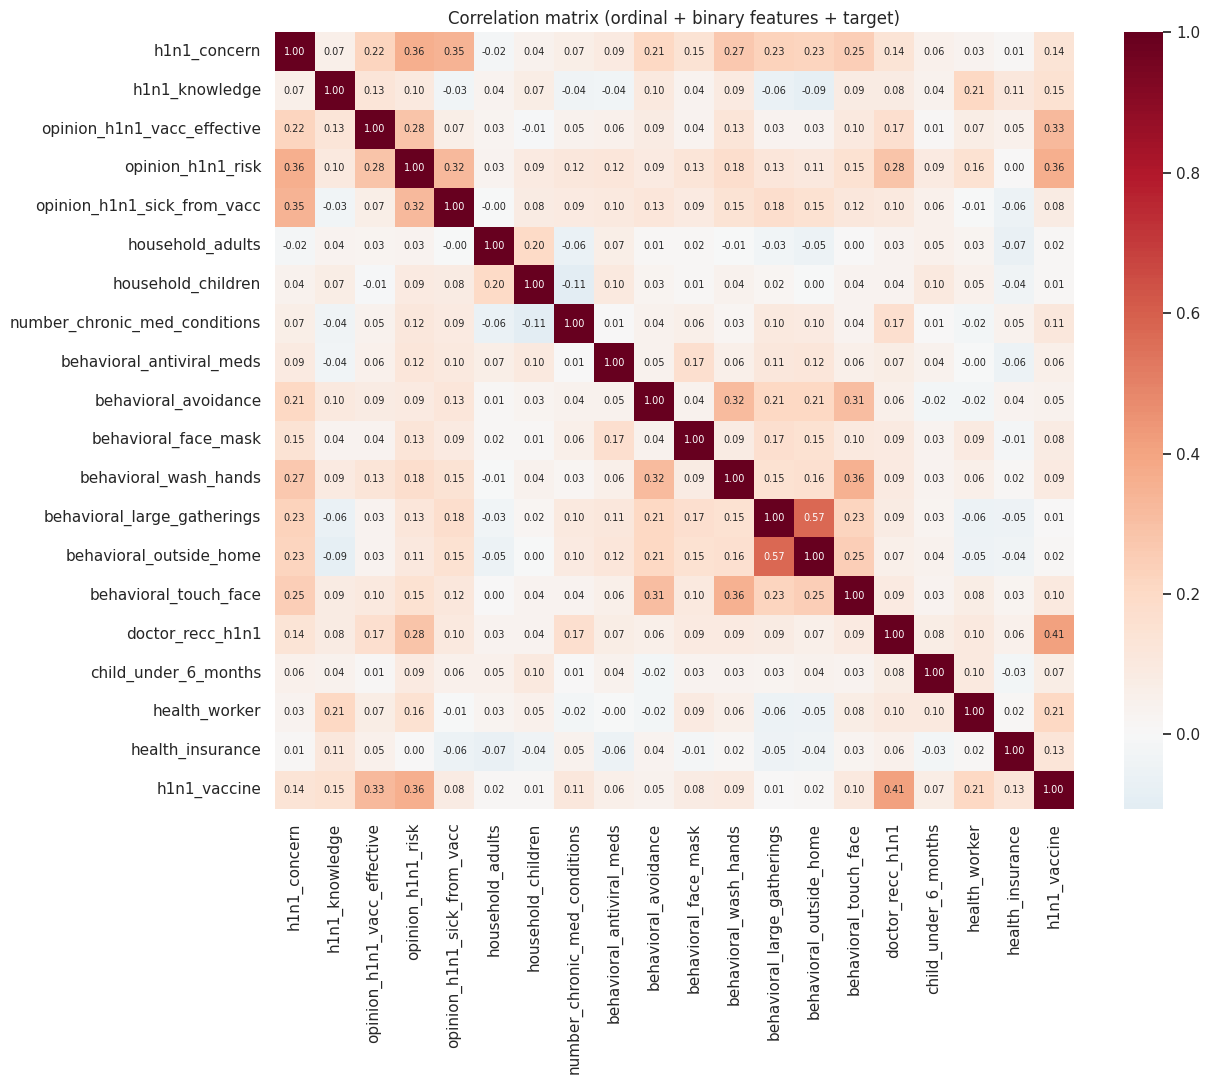

Strongest correlations with the target (absolute value):
doctor_recc_h1n1                 0.414
opinion_h1n1_risk                0.362
opinion_h1n1_vacc_effective      0.325
health_worker                    0.205
h1n1_knowledge                   0.149
h1n1_concern                     0.143
health_insurance                 0.129
number_chronic_med_conditions    0.111
behavioral_touch_face            0.103
behavioral_wash_hands            0.093


In [ ]:
corr = train[ORDINAL + BINARY + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlation matrix (ordinal + binary features + target)')
plt.tight_layout()
plt.show()

print('Strongest correlations with the target (absolute value):')
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(10).round(3).to_string())

### 2.6 Risk profile of the town
Hospitalisation risk depends mainly on age and chronic conditions, so we look at how many high-risk people there are and whether they tend to get vaccinated. This feeds into the cost model later.

In [ ]:
print('Age group distribution:')
print(train['age_group'].value_counts(normalize=True).round(3).to_string())

print('\nNumber of chronic conditions:')
print(train['number_chronic_med_conditions'].value_counts(normalize=True).sort_index().round(3).to_string())

print('\nVaccination rate by age group x number of chronic conditions:')
pd.crosstab(train['age_group'], train['number_chronic_med_conditions'],
            values=train[TARGET], aggfunc='mean').round(2)

Age group distribution:
age_group
65+ Years        0.258
55 - 64 Years    0.224
45 - 54 Years    0.192
18 - 34 Years    0.188
35 - 44 Years    0.139

Number of chronic conditions:
number_chronic_med_conditions
0    0.697
1    0.234
2    0.054
3    0.013
4    0.002
5    0.000
6    0.000

Vaccination rate by age group x number of chronic conditions:


number_chronic_med_conditions,0,1,2,3,4,5,6
age_group,,,,,,,
18 - 34 Years,0.35,0.43,0.54,0.50,1.00,NaN,NaN
35 - 44 Years,0.37,0.51,0.43,0.60,NaN,NaN,NaN
45 - 54 Years,0.33,0.45,0.57,0.64,0.00,NaN,NaN
55 - 64 Years,0.38,0.48,0.42,0.71,0.67,1.0,1.0
65+ Years,0.38,0.43,0.57,0.52,0.25,NaN,NaN


## 3. Preprocessing

Design choices, based on the EDA:
- **Missing values are informative:** missing `health_insurance` gives a 24% vaccination rate vs 50% when present, and missing `doctor_recc_h1n1` gives 18% vs 41%. Numeric/binary features are imputed with the median, **plus an extra 0/1 "was missing" indicator column**, so the model keeps that signal.
- **Categorical features:** missing values become their own `"missing"` category, then one-hot encoding.
- **Rare categories:** some employment sectors have very few people (e.g. energy n=1), so categories with fewer than 20 people are grouped into an "infrequent" bucket to avoid overfitting.
- **Scaling:** numeric features are standardised. This helps logistic regression and is harmless for tree models.
- **No leakage:** everything sits inside a `Pipeline`, so imputation and scaling are learned only from the training folds during cross-validation.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def build_preprocessor():
    """Impute, add missing-value indicators, scale numeric features and one-hot encode categoricals."""
    numeric_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),  # adds a 0/1 column per feature with gaps
        ('scale', StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20)),
    ])
    return ColumnTransformer([
        ('num', numeric_pipe, ORDINAL + BINARY),
        ('cat', categorical_pipe, CATEGORICAL),
    ])

### 3.1 Train / hold-out split

25% of the labelled data is held out as a **final test set** and is not touched until the very end. All model selection, hyperparameter tuning and threshold choice use 5-fold cross-validation on the remaining 75% (the *development set*), so the hold-out result is an honest estimate of real performance.

The split is **stratified** so both parts keep the same 39% vaccination rate.

In [ ]:
X = train[FEATURES]
y = train[TARGET]

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print('Development set:', X_dev.shape, '  vaccination rate:', round(y_dev.mean(), 3))
print('Hold-out set:   ', X_hold.shape, '  vaccination rate:', round(y_hold.mean(), 3))

# 5-fold stratified cross-validation, reused for every model
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Development set: (3567, 29)   vaccination rate: 0.394
Hold-out set:    (1189, 29)   vaccination rate: 0.394


### 3.2 Check the preprocessed output
Fit the preprocessor on the development set and inspect the resulting features: missing indicators, one-hot columns and the grouped rare categories.

In [ ]:
pre = build_preprocessor().fit(X_dev)
X_dev_processed = pre.transform(X_dev)

feature_names = pre.get_feature_names_out()
print('Features before preprocessing:', X_dev.shape[1])
print('Features after preprocessing: ', X_dev_processed.shape[1])

print('\nMissing-value indicator columns:')
print([f for f in feature_names if 'missingindicator' in f])

print('\nEmployment sector columns (rare sectors grouped as "infrequent"):')
print([f for f in feature_names if 'employment_sector' in f])

# Sanity check: no NaNs should remain
X_dense = X_dev_processed.toarray() if hasattr(X_dev_processed, 'toarray') else X_dev_processed
print('\nNaNs remaining after preprocessing:', np.isnan(X_dense).sum())

Features before preprocessing: 29
Features after preprocessing:  90

Missing-value indicator columns:
['num__missingindicator_h1n1_concern', 'num__missingindicator_h1n1_knowledge', 'num__missingindicator_opinion_h1n1_vacc_effective', 'num__missingindicator_opinion_h1n1_risk', 'num__missingindicator_opinion_h1n1_sick_from_vacc', 'num__missingindicator_household_adults', 'num__missingindicator_household_children', 'num__missingindicator_behavioral_antiviral_meds', 'num__missingindicator_behavioral_avoidance', 'num__missingindicator_behavioral_face_mask', 'num__missingindicator_behavioral_wash_hands', 'num__missingindicator_behavioral_large_gatherings', 'num__missingindicator_behavioral_outside_home', 'num__missingindicator_behavioral_touch_face', 'num__missingindicator_doctor_recc_h1n1', 'num__missingindicator_child_under_6_months', 'num__missingindicator_health_worker', 'num__missingindicator_health_insurance']

Employment sector columns (rare sectors grouped as "infrequent"):
['cat__em

## 4. Cost function

### 4.1 What happens to each person

| Truth \ Decision | Vaccine sent | No vaccine sent |
|---|---|---|
| **Wants vaccine** | TP: $500, **protected** | FN: $500 paid as cash, **not protected** |
| **Doesn't want vaccine** | FP: $500 **wasted dose**, not protected | TN: $0, not protected |

*Assumption:* someone paid cash instead of receiving a dose stays unvaccinated.

Therefore:
- **Vaccine cost** = $500 × (TP + FN + FP). TP + FN (everyone who wants one) is fixed, so the model can only reduce **wasted doses (FP)**.
- **Hospitalisation cost** = $25,000 × Σ P(hospitalised)ᵢ, which is lower only for **TPs** (people who actually received a dose they wanted).

**The trade-off:** sending more vaccines protects more true wanters (fewer FN) but wastes more doses (more FP).

### 4.2 Hospitalisation probability (estimated with generative AI)

As the brief instructs, hospitalisation probabilities were estimated by asking several AIs the same question and comparing the answers. Prompt used:

> *"Assume everyone in a town is infected with 2009 pandemic H1N1 influenza. For an unvaccinated healthy adult aged 35–54, what is the probability of hospitalisation? Give a relative-risk multiplier for each age group (18–34, 35–44, 45–54, 55–64, 65+), the extra relative risk per chronic medical condition (asthma, diabetes, heart, kidney, etc.), and the vaccine's effectiveness at preventing hospitalisation. Give single numbers and cite sources."*

Model used:

P(hosp)ᵢ = base × age_multᵢ × (1 + k × chronicᵢ) × (1 − e × vaccinatedᵢ)

Each AI's answers are recorded below, and the **median** across AIs is used so that no single answer dominates.

In [ ]:
VACCINE_COST = 500
HOSP_COST = 25_000

AGE_GROUPS = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']

# ---- Record each AI's answers here (copy the numbers from Gemini, ChatGPT, Claude, etc.) ----
# Each entry: base risk, age multipliers (same order as AGE_GROUPS), extra risk per chronic condition, vaccine effectiveness
AI_ESTIMATES = {
    'Claude': {'base_risk': 0.005, 'age_mult': [0.8, 1.0, 1.0, 1.3, 2.0],
                                      'chronic_k': 0.5, 'vacc_eff': 0.60},
       'ChatGPT': {'base_risk': 0.005, 'age_mult': [0.8, 1.0, 1.2, 1.7, 2.5],
               'chronic_k': 0.5, 'vacc_eff': 0.50},
   'Gemini':  {'base_risk': 0.015, 'age_mult': [0.8, 1.0, 1.2, 1.67, 2.0],
                'chronic_k': 0.25, 'vacc_eff': 0.65},
    # 'Claude':  {'base_risk': ..., 'age_mult': [...], 'chronic_k': ..., 'vacc_eff': ...},
}

def combine_estimates(estimates):
    """Take the median of each parameter across all AI answers (robust to one outlier)."""
    vals = list(estimates.values())
    return {
        'base_risk': float(np.median([v['base_risk'] for v in vals])),
        'age_mult': dict(zip(AGE_GROUPS, np.median([v['age_mult'] for v in vals], axis=0))),
        'chronic_k': float(np.median([v['chronic_k'] for v in vals])),
        'vacc_eff': float(np.median([v['vacc_eff'] for v in vals])),
    }

# Table comparing the AIs (useful for the report)
display(pd.DataFrame({name: {'base_risk': v['base_risk'], **dict(zip(AGE_GROUPS, v['age_mult'])),
                             'chronic_k': v['chronic_k'], 'vacc_eff': v['vacc_eff']}
                      for name, v in AI_ESTIMATES.items()}))

HOSP_PARAMS = combine_estimates(AI_ESTIMATES)
print('Parameters used in the cost model:')
for k, v in HOSP_PARAMS.items():
    print(f'  {k}: {v}')

,Claude,ChatGPT,Gemini
base_risk,0.005,0.005,0.015
18 - 34 Years,0.800,0.800,0.800
35 - 44 Years,1.000,1.000,1.000
45 - 54 Years,1.000,1.200,1.200
55 - 64 Years,1.300,1.700,1.670
65+ Years,2.000,2.500,2.000
chronic_k,0.500,0.500,0.250
vacc_eff,0.600,0.500,0.650


Parameters used in the cost model:
  base_risk: 0.005
  age_mult: {'18 - 34 Years': np.float64(0.8), '35 - 44 Years': np.float64(1.0), '45 - 54 Years': np.float64(1.2), '55 - 64 Years': np.float64(1.67), '65+ Years': np.float64(2.0)}
  chronic_k: 0.5
  vacc_eff: 0.6


### 4.3 Cost functions

Mean hospitalisation risk if unvaccinated: 0.0085
Range: 0.0040 to 0.0334


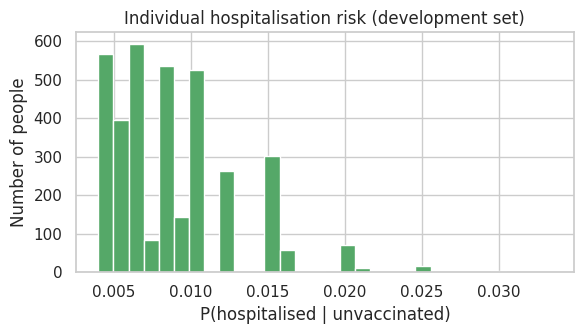

In [ ]:
def hosp_risk_unvaccinated(df, params=None):
    """Probability that each person is hospitalised if they are NOT vaccinated."""
    params = params or HOSP_PARAMS
    age_mult = df['age_group'].map(params['age_mult']).fillna(1.0).values
    chronic = df['number_chronic_med_conditions'].fillna(0).values
    risk = params['base_risk'] * age_mult * (1 + params['chronic_k'] * chronic)
    return np.clip(risk, 0, 1)


def town_cost(y_true, y_send, risk_unvacc, params=None):
    """
    Total town cost.
    y_true: 1 if the person actually wants a vaccine
    y_send: 1 if we post them a vaccine
    risk_unvacc: each person's hospitalisation probability if unvaccinated
    """
    params = params or HOSP_PARAMS
    y_true = np.asarray(y_true).astype(int)
    y_send = np.asarray(y_send).astype(int)

    tp = (y_true == 1) & (y_send == 1)   # wanted it, got it -> protected
    fn = (y_true == 1) & (y_send == 0)   # wanted it, paid cash -> not protected
    fp = (y_true == 0) & (y_send == 1)   # didn't want it, dose wasted
    tn = (y_true == 0) & (y_send == 0)

    vaccine_cost = VACCINE_COST * (tp.sum() + fn.sum() + fp.sum())
    hosp_prob = np.where(tp, risk_unvacc * (1 - params['vacc_eff']), risk_unvacc)
    hosp_cost = HOSP_COST * hosp_prob.sum()

    return {'total': vaccine_cost + hosp_cost, 'vaccine': vaccine_cost, 'hospital': hosp_cost,
            'TP': int(tp.sum()), 'FN': int(fn.sum()), 'FP': int(fp.sum()), 'TN': int(tn.sum()),
            'sent': int(y_send.sum())}


risk_dev = hosp_risk_unvaccinated(X_dev)
risk_hold = hosp_risk_unvaccinated(X_hold)

print(f'Mean hospitalisation risk if unvaccinated: {risk_dev.mean():.4f}')
print(f'Range: {risk_dev.min():.4f} to {risk_dev.max():.4f}')

plt.figure(figsize=(6, 3.5))
plt.hist(risk_dev, bins=30, color='#55A868')
plt.xlabel('P(hospitalised | unvaccinated)')
plt.ylabel('Number of people')
plt.title('Individual hospitalisation risk (development set)')
plt.tight_layout()
plt.show()

### 4.4 Reference strategies (no model)
Before building a model, we price three simple strategies on the development set. These set the scale: a useful model must beat "send to nobody" and "send to everybody", and the oracle is the best possible result.
- **Send to nobody:** no doses wasted, but nobody is protected.
- **Send to everybody:** every wanter is protected, but every non-wanter's dose is wasted.
- **Oracle:** we know exactly who wants a vaccine (theoretical best).

In [ ]:
reference = pd.DataFrame({
    'Send to nobody':    town_cost(y_dev, np.zeros(len(y_dev)), risk_dev),
    'Send to everybody': town_cost(y_dev, np.ones(len(y_dev)), risk_dev),
    'Oracle (perfect)':  town_cost(y_dev, y_dev.values, risk_dev),
}).T

display(reference[['total', 'vaccine', 'hospital', 'sent', 'TP', 'FN', 'FP']]
        .style.format({c: '${:,.0f}' for c in ['total', 'vaccine', 'hospital']}))

gap = reference.loc['Send to nobody', 'total'] - reference.loc['Oracle (perfect)', 'total']
print(f'Maximum possible saving vs "send to nobody": ${gap:,.0f}')

,total,vaccine,hospital,sent,TP,FN,FP
Send to nobody,"$1,462,788","$703,000","$759,788",0.000000,0.000000,1406.000000,0.000000
Send to everybody,"$2,354,686","$1,783,500","$571,186",3567.000000,1406.000000,0.000000,2161.000000
Oracle (perfect),"$1,274,186","$703,000","$571,186",1406.000000,1406.000000,0.000000,0.000000


Maximum possible saving vs "send to nobody": $188,602


### 4.5 Cost-optimal decision for one person

For a person with acceptance probability *p* and unvaccinated risk *r*, posting them a vaccine:
- if they want it (probability *p*): saves 25,000 × r × e in expected hospital costs (the $500 is paid either way);
- if they don't (probability 1 − p): wastes $500.

So a vaccine should be sent when

p × 25,000 × r × e > (1 − p) × 500   ⟺   **p > t = 500 / (500 + 25,000 × r × e)**

Each person gets their own threshold, and **high-risk people get a lower one**. This only works if the model's probabilities are well calibrated, which we check after training.

In [ ]:
def risk_aware_threshold(risk_unvacc, params=None):
    """Per-person probability cut-off above which sending a vaccine lowers expected cost."""
    params = params or HOSP_PARAMS
    benefit = HOSP_COST * risk_unvacc * params['vacc_eff']   # expected hospital saving if a wanter is protected
    return VACCINE_COST / (VACCINE_COST + benefit)

t_dev = risk_aware_threshold(risk_dev)
print(f'Per-person thresholds: {t_dev.min():.2f} (highest-risk person) to {t_dev.max():.2f} (lowest-risk person)')

# Threshold for each age group x chronic-condition combination
grid = pd.DataFrame([(a, c) for a in AGE_GROUPS for c in range(4)],
                    columns=['age_group', 'number_chronic_med_conditions'])
grid['threshold'] = risk_aware_threshold(hosp_risk_unvaccinated(grid))
grid.pivot(index='age_group', columns='number_chronic_med_conditions', values='threshold').round(2)

Per-person thresholds: 0.50 (highest-risk person) to 0.89 (lowest-risk person)


number_chronic_med_conditions,0,1,2,3
age_group,,,,
18 - 34 Years,0.89,0.85,0.81,0.77
35 - 44 Years,0.87,0.82,0.77,0.73
45 - 54 Years,0.85,0.79,0.74,0.69
55 - 64 Years,0.80,0.73,0.67,0.61
65+ Years,0.77,0.69,0.62,0.57


## 5. Baseline models

Three model families, compared with 5-fold cross-validated ROC-AUC on the development set:
- **Logistic regression:** simple, interpretable, and its probabilities are usually well calibrated.
- **Random forest:** an ensemble of decision trees that captures non-linear effects and interactions.
- **XGBoost:** gradient-boosted trees, typically the strongest model family on tabular data.

ROC-AUC measures how well a model *ranks* people by their likelihood of vaccinating, independent of any threshold. That suits our task, because the threshold is chosen later from the costs.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def make_pipe(clf):
    """Wrap a classifier with the preprocessing steps from Section 3."""
    return Pipeline([('pre', build_preprocessor()), ('clf', clf)])

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
}

baseline_scores = {}
for name, clf in baseline_models.items():
    scores = cross_val_score(make_pipe(clf), X_dev, y_dev, cv=CV, scoring='roc_auc', n_jobs=-1)
    baseline_scores[name] = scores
    print(f'{name:20s} AUC = {scores.mean():.4f} ± {scores.std():.4f}')

Logistic Regression  AUC = 0.8465 ± 0.0194
Random Forest        AUC = 0.8490 ± 0.0191
XGBoost              AUC = 0.8472 ± 0.0212


## 6. Hyperparameter tuning

`RandomizedSearchCV` samples 30 hyperparameter combinations per model and scores each one with 5-fold CV ROC-AUC. Random search explores wide ranges more efficiently than a full grid search (Bergstra & Bengio, 2012).

What is tuned:
- **Logistic regression:** regularisation strength `C`, L1 vs L2 penalty, class weighting.
- **Random forest:** number of trees, depth, minimum samples per leaf, features considered per split.
- **XGBoost:** number of trees, learning rate, depth, minimum child weight, row/column subsampling, L2 regularisation.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

search_spaces = {
    'Logistic Regression': (
        LogisticRegression(max_iter=5000, solver='liblinear'),
        {'clf__C': loguniform(1e-3, 1e2),
         'clf__penalty': ['l1', 'l2'],
         'clf__class_weight': [None, 'balanced']},
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'clf__n_estimators': randint(200, 600),
         'clf__max_depth': [4, 6, 8, 10, 14, None],
         'clf__min_samples_leaf': randint(1, 20),
         'clf__max_features': ['sqrt', 'log2', 0.3, 0.5]},
    ),
    'XGBoost': (
        XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
        {'clf__n_estimators': randint(100, 600),
         'clf__learning_rate': loguniform(0.01, 0.2),
         'clf__max_depth': randint(2, 7),
         'clf__min_child_weight': randint(1, 10),
         'clf__subsample': uniform(0.6, 0.4),          # samples from 0.6 to 1.0
         'clf__colsample_bytree': uniform(0.5, 0.5),   # samples from 0.5 to 1.0
         'clf__reg_lambda': loguniform(0.1, 10)},
    ),
}

N_ITER = 30   # lower this (e.g. 15) if Colab is slow
tuned = {}

for name, (clf, params) in search_spaces.items():
    search = RandomizedSearchCV(make_pipe(clf), params, n_iter=N_ITER, scoring='roc_auc',
                                cv=CV, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_dev, y_dev)
    tuned[name] = search
    print(f'\n{name}: best CV AUC = {search.best_score_:.4f}  (baseline {baseline_scores[name].mean():.4f})')
    for k, v in search.best_params_.items():
        print(f'   {k}: {v}')


Logistic Regression: best CV AUC = 0.8510  (baseline 0.8465)
   clf__C: 0.009962513222055111
   clf__class_weight: None
   clf__penalty: l2

Random Forest: best CV AUC = 0.8536  (baseline 0.8490)
   clf__max_depth: 10
   clf__max_features: sqrt
   clf__min_samples_leaf: 1
   clf__n_estimators: 513

XGBoost: best CV AUC = 0.8535  (baseline 0.8472)
   clf__colsample_bytree: 0.647816842918857
   clf__learning_rate: 0.01371674915054392
   clf__max_depth: 5
   clf__min_child_weight: 4
   clf__n_estimators: 385
   clf__reg_lambda: 5.8419860801980095
   clf__subsample: 0.7297380084021096


### 6.1 Baseline vs tuned comparison

,Baseline AUC,Baseline std,Tuned AUC,Tuned std,Improvement
Logistic Regression,0.8465,0.0194,0.8510,0.0184,0.0045
Random Forest,0.8490,0.0191,0.8536,0.0194,0.0046
XGBoost,0.8472,0.0212,0.8535,0.0186,0.0062


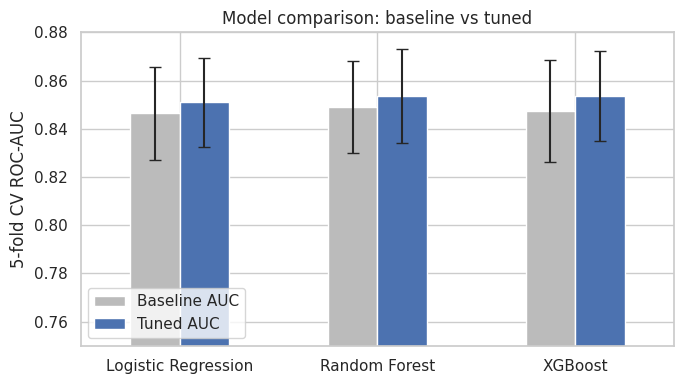

In [ ]:
summary = pd.DataFrame({
    'Baseline AUC': {n: s.mean() for n, s in baseline_scores.items()},
    'Baseline std': {n: s.std() for n, s in baseline_scores.items()},
    'Tuned AUC': {n: s.best_score_ for n, s in tuned.items()},
    'Tuned std': {n: s.cv_results_['std_test_score'][s.best_index_] for n, s in tuned.items()},
})
summary['Improvement'] = summary['Tuned AUC'] - summary['Baseline AUC']
display(summary.round(4))

ax = summary[['Baseline AUC', 'Tuned AUC']].plot(kind='bar', figsize=(7, 4),
                                                  yerr=summary[['Baseline std', 'Tuned std']].values.T,
                                                  color=['#BBBBBB', '#4C72B0'], capsize=4)
ax.set_ylim(0.75, 0.88)
ax.set_ylabel('5-fold CV ROC-AUC')
ax.set_title('Model comparison: baseline vs tuned')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 7. Probability calibration

The cost-based decision uses predicted probabilities directly (vaccine sent if p > threshold), so they must be trustworthy: among people given p = 0.7, about 70% should actually vaccinate.

We generate **out-of-fold (OOF)** predictions on the development set, so each person is predicted by a model that never saw them during training. We then compare each tuned model with an isotonic-calibrated version:
- **Brier score:** mean squared error of the probabilities (lower is better).
- **Calibration curve:** predicted vs observed vaccination rate (closer to the diagonal is better).

,OOF AUC,Brier score
Random Forest (calibrated),0.8529,0.1480
XGBoost (raw),0.8531,0.1481
XGBoost (calibrated),0.8513,0.1488
Logistic Regression (calibrated),0.8477,0.1507
Logistic Regression (raw),0.8506,0.1509
Random Forest (raw),0.8535,0.1554


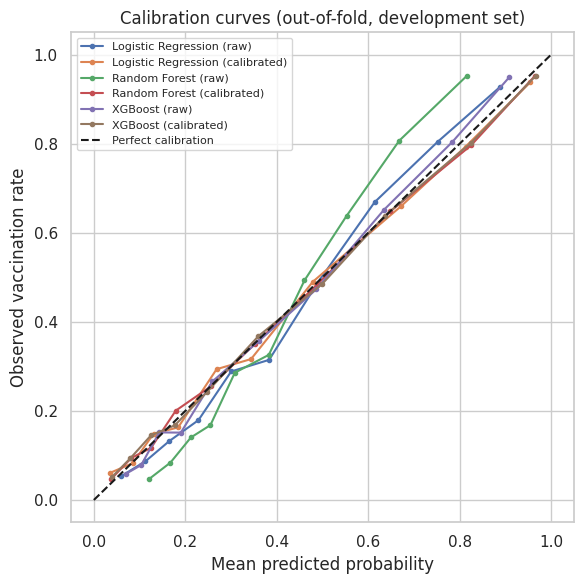

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss

oof = {}
for name, search in tuned.items():
    best = search.best_estimator_
    # Raw probabilities from the tuned model
    oof[f'{name} (raw)'] = cross_val_predict(best, X_dev, y_dev, cv=CV,
                                             method='predict_proba', n_jobs=-1)[:, 1]
    # Isotonic-calibrated probabilities
    calibrated = CalibratedClassifierCV(best, method='isotonic', cv=5)
    oof[f'{name} (calibrated)'] = cross_val_predict(calibrated, X_dev, y_dev, cv=CV,
                                                    method='predict_proba', n_jobs=-1)[:, 1]

calib_table = pd.DataFrame({
    'OOF AUC': {k: roc_auc_score(y_dev, p) for k, p in oof.items()},
    'Brier score': {k: brier_score_loss(y_dev, p) for k, p in oof.items()},
}).sort_values('Brier score')
display(calib_table.round(4))

fig, ax = plt.subplots(figsize=(6, 6))
for k, p in oof.items():
    frac_pos, mean_pred = calibration_curve(y_dev, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', markersize=3, label=k)
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed vaccination rate')
ax.set_title('Calibration curves (out-of-fold, development set)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Choosing who gets a vaccine

Each model gives every person a probability of accepting a vaccine. We compare two ways of turning those probabilities into "send / don't send" decisions:

- **A. Global threshold:** one cut-off for everybody (e.g. send if p > 0.6). We try every value from 0.05 to 0.95 and keep the cheapest.
- **B. Risk-aware threshold:** each person gets their own cut-off from Section 4.5, t = 500 / (500 + 25,000 × risk × effectiveness). High-risk people get lower cut-offs. Nothing is tuned; it follows directly from the costs.

All decisions are made on **out-of-fold** predictions from the development set (Section 7), so every person is scored by a model that never saw them. The hold-out set is still untouched.

We also report **% of possible saving captured**: how much of the gap between "send to nobody" and the perfect oracle each approach closes.

In [ ]:
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)

# Recompute risks and per-person thresholds with the final (median) AI parameters
risk_dev = hosp_risk_unvaccinated(X_dev)
t_dev = risk_aware_threshold(risk_dev)

# Reference points for "% of possible saving"
cost_nobody = town_cost(y_dev, np.zeros(len(y_dev)), risk_dev)['total']
cost_oracle = town_cost(y_dev, y_dev.values, risk_dev)['total']

def pct_saving(cost):
    """Share of the gap between 'send to nobody' and the perfect oracle that a strategy closes."""
    return 100 * (cost_nobody - cost) / (cost_nobody - cost_oracle)

def scan_global_threshold(y_true, proba, risk):
    """Total cost for every global threshold from 0.05 to 0.95."""
    rows = []
    for t in THRESHOLDS:
        c = town_cost(y_true, (proba >= t).astype(int), risk)
        rows.append({'threshold': t, **c})
    return pd.DataFrame(rows)

decision_rows, scans = [], {}
for model_name, p in oof.items():
    scan = scan_global_threshold(y_dev, p, risk_dev)
    scans[model_name] = scan
    best = scan.loc[scan['total'].idxmin()]
    risk_aware = town_cost(y_dev, (p >= t_dev).astype(int), risk_dev)
    decision_rows.append({
        'model': model_name,
        'best global threshold': best['threshold'],
        'cost (global)': best['total'],
        'cost (risk-aware)': risk_aware['total'],
        '% saving (risk-aware)': pct_saving(risk_aware['total']),
        'doses sent (risk-aware)': risk_aware['sent'],
        'wasted (FP)': risk_aware['FP'],
    })

decision_table = pd.DataFrame(decision_rows).sort_values('cost (risk-aware)').reset_index(drop=True)
print(f'Send to nobody: ${cost_nobody:,.0f}   |   Oracle: ${cost_oracle:,.0f}   |   People: {len(y_dev)}')
display(decision_table.style.format({'cost (global)': '${:,.0f}', 'cost (risk-aware)': '${:,.0f}',
                                     'best global threshold': '{:.2f}', '% saving (risk-aware)': '{:.1f}%'}))

Send to nobody: $1,462,788   |   Oracle: $1,274,186   |   People: 3567


,model,best global threshold,cost (global),cost (risk-aware),% saving (risk-aware),doses sent (risk-aware),wasted (FP)
0,XGBoost (calibrated),0.79,"$1,411,892","$1,410,305",27.8%,591,60
1,XGBoost (raw),0.76,"$1,412,664","$1,411,713",27.1%,508,49
2,Random Forest (calibrated),0.85,"$1,411,188","$1,412,972",26.4%,588,63
3,Logistic Regression (calibrated),0.77,"$1,418,988","$1,414,424",25.6%,593,70
4,Logistic Regression (raw),0.73,"$1,418,790","$1,416,298",24.6%,434,40
5,Random Forest (raw),0.64,"$1,411,300","$1,424,391",20.4%,256,14


### 8.1 Cost vs. threshold for the best model

The U-shaped curve shows the trade-off. A low threshold sends many doses to people who don't want them (vaccine cost rises); a high threshold leaves willing people unprotected (hospital cost rises). The dashed purple line shows the risk-aware rule for comparison.

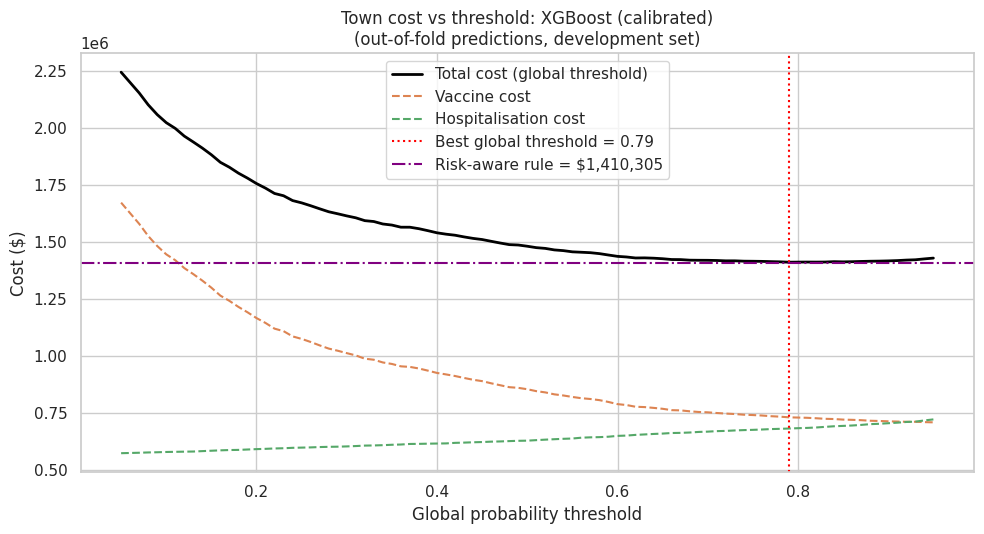

Selected model: XGBoost (calibrated)
Global threshold 0.79: $1,411,892
Risk-aware rule:            $1,410,305


In [ ]:
best_key = decision_table.iloc[0]['model']
scan = scans[best_key]
best_t = scan.loc[scan['total'].idxmin(), 'threshold']
risk_aware_cost = decision_table.iloc[0]['cost (risk-aware)']

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(scan['threshold'], scan['total'], color='black', linewidth=2, label='Total cost (global threshold)')
ax.plot(scan['threshold'], scan['vaccine'], '--', color='#DD8452', label='Vaccine cost')
ax.plot(scan['threshold'], scan['hospital'], '--', color='#55A868', label='Hospitalisation cost')
ax.axvline(best_t, color='red', linestyle=':', label=f'Best global threshold = {best_t:.2f}')
ax.axhline(risk_aware_cost, color='purple', linestyle='-.', label=f'Risk-aware rule = ${risk_aware_cost:,.0f}')
ax.set_xlabel('Global probability threshold')
ax.set_ylabel('Cost ($)')
ax.set_title(f'Town cost vs threshold: {best_key}\n(out-of-fold predictions, development set)')
ax.legend()
plt.tight_layout()
plt.show()

print('Selected model:', best_key)
print(f'Global threshold {best_t:.2f}: ${scan["total"].min():,.0f}')
print(f'Risk-aware rule:            ${risk_aware_cost:,.0f}')

## 9. Final evaluation on the hold-out set

The selected model (calibrated XGBoost with the risk-aware rule) is now refit on the full development set and tested **once** on the 1,189 hold-out people, who have not been used for any decision so far. This gives an honest estimate of performance on new people.

For comparison:
- **Send to nobody:** no wasted doses, but nobody is protected.
- **Send to everybody:** every willing person is protected, but every unwilling person's dose is wasted.
- **Model with the best global threshold** (chosen in Section 8).
- **Model with the risk-aware rule.**
- **Oracle:** perfect knowledge of who wants a vaccine (the best possible result).

In [ ]:
from sklearn.metrics import confusion_matrix

def build_final_model(key):
    """Rebuild the selected model (with or without calibration) from its tuned pipeline."""
    base_name = key.replace(' (raw)', '').replace(' (calibrated)', '')
    est = tuned[base_name].best_estimator_
    if key.endswith('(calibrated)'):
        return CalibratedClassifierCV(est, method='isotonic', cv=5)
    return est

final_model = build_final_model(best_key).fit(X_dev, y_dev)
p_hold = final_model.predict_proba(X_hold)[:, 1]

risk_hold = hosp_risk_unvaccinated(X_hold)
t_hold = risk_aware_threshold(risk_hold)

strategies = {
    'Send to nobody':                  np.zeros(len(y_hold), dtype=int),
    'Send to everybody':               np.ones(len(y_hold), dtype=int),
    f'Model, global t = {best_t:.2f}': (p_hold >= best_t).astype(int),
    'Model, risk-aware':               (p_hold >= t_hold).astype(int),
    'Oracle (perfect)':                y_hold.values,
}

hold_results = pd.DataFrame({k: town_cost(y_hold, v, risk_hold) for k, v in strategies.items()}).T
nobody, oracle = hold_results.loc['Send to nobody', 'total'], hold_results.loc['Oracle (perfect)', 'total']
hold_results['saving vs nobody'] = nobody - hold_results['total']
hold_results['% of possible saving'] = 100 * hold_results['saving vs nobody'] / (nobody - oracle)
hold_results['cost per person'] = hold_results['total'] / len(y_hold)

print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}   |   People: {len(y_hold)}')
display(hold_results[['total', 'cost per person', 'vaccine', 'hospital', 'saving vs nobody',
                      '% of possible saving', 'sent', 'TP', 'FN', 'FP', 'TN']]
        .style.format({'total': '${:,.0f}', 'cost per person': '${:,.2f}', 'vaccine': '${:,.0f}',
                       'hospital': '${:,.0f}', 'saving vs nobody': '${:,.0f}',
                       '% of possible saving': '{:.1f}%'}))

Hold-out AUC: 0.8468   |   People: 1189


,total,cost per person,vaccine,hospital,saving vs nobody,% of possible saving,sent,TP,FN,FP,TN
Send to nobody,"$492,873",$414.53,"$234,000","$258,873",$0,0.0%,0.000000,0.000000,468.000000,0.000000,721.000000
Send to everybody,"$787,869",$662.63,"$594,500","$193,369","$-294,996",-450.3%,1189.000000,468.000000,0.000000,721.000000,0.000000
"Model, global t = 0.79","$477,270",$401.40,"$243,000","$234,270","$15,603",23.8%,188.000000,170.000000,298.000000,18.000000,703.000000
"Model, risk-aware","$475,919",$400.27,"$242,500","$233,419","$16,954",25.9%,176.000000,159.000000,309.000000,17.000000,704.000000
Oracle (perfect),"$427,369",$359.44,"$234,000","$193,369","$65,504",100.0%,468.000000,468.000000,0.000000,0.000000,721.000000


### 9.1 Visual comparison

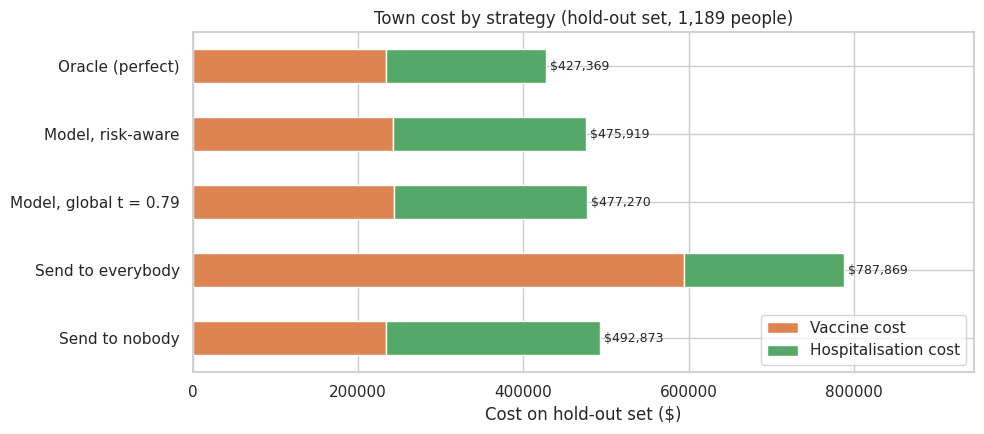

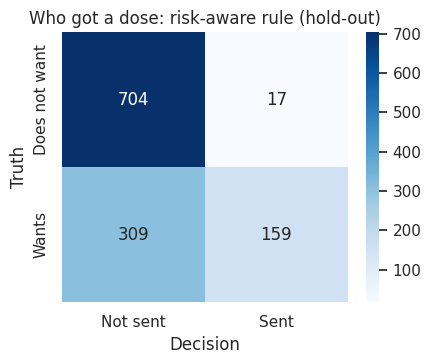

Share of each age group sent a dose (hold-out):
age_group
18 - 34 Years    0.102
35 - 44 Years    0.101
45 - 54 Years    0.137
55 - 64 Years    0.177
65+ Years        0.185


In [ ]:
# Stacked bar: vaccine vs hospital cost for each strategy
fig, ax = plt.subplots(figsize=(10, 4.5))
hold_results[['vaccine', 'hospital']].plot(kind='barh', stacked=True, ax=ax, color=['#DD8452', '#55A868'])
for i, total in enumerate(hold_results['total']):
    ax.text(total + 5000, i, f'${total:,.0f}', va='center', fontsize=9)
ax.set_xlabel('Cost on hold-out set ($)')
ax.set_title('Town cost by strategy (hold-out set, 1,189 people)')
ax.set_xlim(0, hold_results['total'].max() * 1.2)
ax.legend(['Vaccine cost', 'Hospitalisation cost'], loc='lower right')
plt.tight_layout()
plt.show()

# Confusion matrix for the risk-aware rule
cm = confusion_matrix(y_hold, strategies['Model, risk-aware'])
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not sent', 'Sent'], yticklabels=['Does not want', 'Wants'])
plt.title('Who got a dose: risk-aware rule (hold-out)')
plt.ylabel('Truth')
plt.xlabel('Decision')
plt.tight_layout()
plt.show()

# Which age groups received doses?
sent_mask = strategies['Model, risk-aware'] == 1
print('Share of each age group sent a dose (hold-out):')
print(pd.Series(sent_mask, index=X_hold.index).groupby(X_hold['age_group']).mean().round(3).to_string())

## 10. Sensitivity analysis: how much do the hospitalisation assumptions matter?

The hospitalisation parameters came from generative AI and are uncertain: Claude and ChatGPT gave a 0.5% baseline risk, Gemini gave 1.5%. A result that only holds under one set of assumptions is not robust.

Two checks are done on the hold-out set. The acceptance model stays the same; only the hospital assumptions change:
1. **Each AI's own parameters:** what happens if Claude, ChatGPT or Gemini alone is right?
2. **A grid of baseline risks and vaccine effectiveness values:** from 0.2% to 6% baseline (covering Gemini's 1.5% and the team's earlier 6% placeholder), and 40–80% effectiveness.

For each scenario we check whether the model still beats "send to nobody" and "send to everybody", and how many doses it sends.

Model is cheapest in 18 of 18 scenarios


,base_risk,vacc_eff,model,send to nobody,send to everybody,oracle,% of possible saving,doses sent,share sent,model is cheapest
0,0.002000,0.400000,"$337,160","$337,549","$680,582","$320,082",2.2%,90,7.6%,True
1,0.002000,0.600000,"$334,628","$337,549","$671,848","$311,348",11.1%,110,9.3%,True
2,0.002000,0.800000,"$331,237","$337,549","$663,114","$302,614",18.1%,123,10.3%,True
3,0.005000,0.400000,"$484,894","$492,873","$809,704","$449,204",18.3%,138,11.6%,True
4,0.005000,0.600000,"$475,919","$492,873","$787,869","$427,369",25.9%,176,14.8%,True
5,0.005000,0.800000,"$464,418","$492,873","$766,035","$405,535",32.6%,213,17.9%,True
6,0.010000,0.400000,"$723,291","$751,746","$1,024,908","$664,408",32.6%,213,17.9%,True
7,0.010000,0.600000,"$698,529","$751,746","$981,238","$620,738",40.6%,260,21.9%,True
8,0.010000,0.800000,"$673,874","$751,746","$937,569","$577,069",44.6%,319,26.8%,True
9,0.015000,0.400000,"$957,402","$1,010,619","$1,240,112","$879,612",40.6%,260,21.9%,True


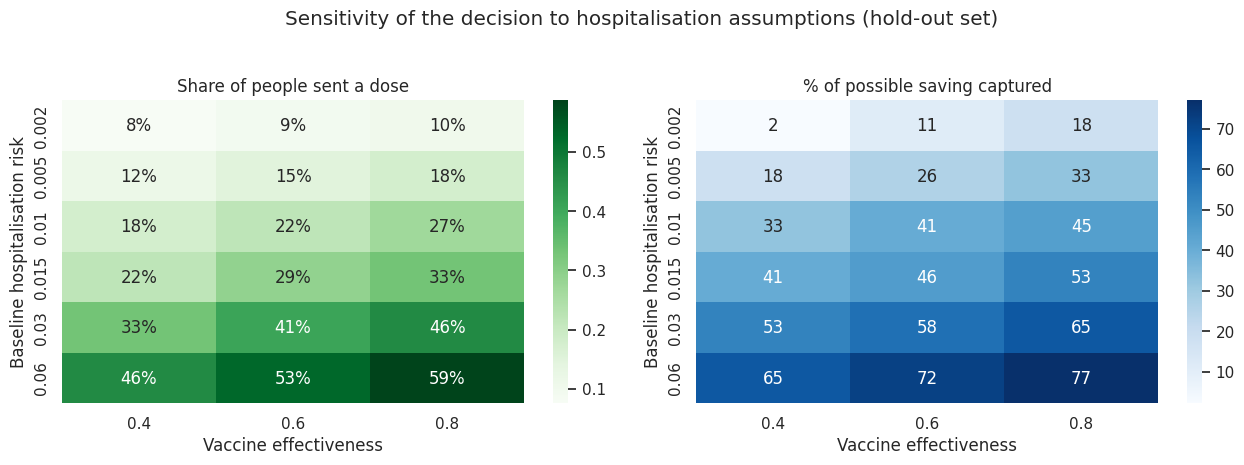

In [ ]:
-# ---- Check 2: grid of baseline risk x vaccine effectiveness (other parameters = median) ----
grid_rows = []
for base in [0.002, 0.005, 0.01, 0.015, 0.03, 0.06]:
    for eff in [0.4, 0.6, 0.8]:
        params = {**HOSP_PARAMS, 'base_risk': base, 'vacc_eff': eff}
        grid_rows.append({'base_risk': base, 'vacc_eff': eff, **evaluate_scenario(params)})
sens = pd.DataFrame(grid_rows)

print(f"Model is cheapest in {sens['model is cheapest'].sum()} of {len(sens)} scenarios")
display(sens.style.format({'model': '${:,.0f}', 'send to nobody': '${:,.0f}', 'send to everybody': '${:,.0f}',
                           'oracle': '${:,.0f}', '% of possible saving': '{:.1f}%', 'share sent': '{:.1%}'}))

# Heatmaps: share of people sent a dose, and % of possible saving captured
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(sens.pivot(index='base_risk', columns='vacc_eff', values='share sent'),
            annot=True, fmt='.0%', cmap='Greens', ax=axes[0])
axes[0].set_title('Share of people sent a dose')
sns.heatmap(sens.pivot(index='base_risk', columns='vacc_eff', values='% of possible saving'),
            annot=True, fmt='.0f', cmap='Blues', ax=axes[1])
axes[1].set_title('% of possible saving captured')
for ax in axes:
    ax.set_xlabel('Vaccine effectiveness')
    ax.set_ylabel('Baseline hospitalisation risk')
plt.suptitle('Sensitivity of the decision to hospitalisation assumptions (hold-out set)', y=1.03)
plt.tight_layout()
plt.show()

## 11. Feature importance

Which survey answers drive the model's predictions? **Permutation importance** shuffles one column at a time on the hold-out set and measures how much the AUC drops. A big drop means the model relies on that feature. It works for any model (including calibrated ones) and gives one score per original column rather than per one-hot dummy.

*Note: this shows what the model uses to predict, not what causes people to vaccinate.*

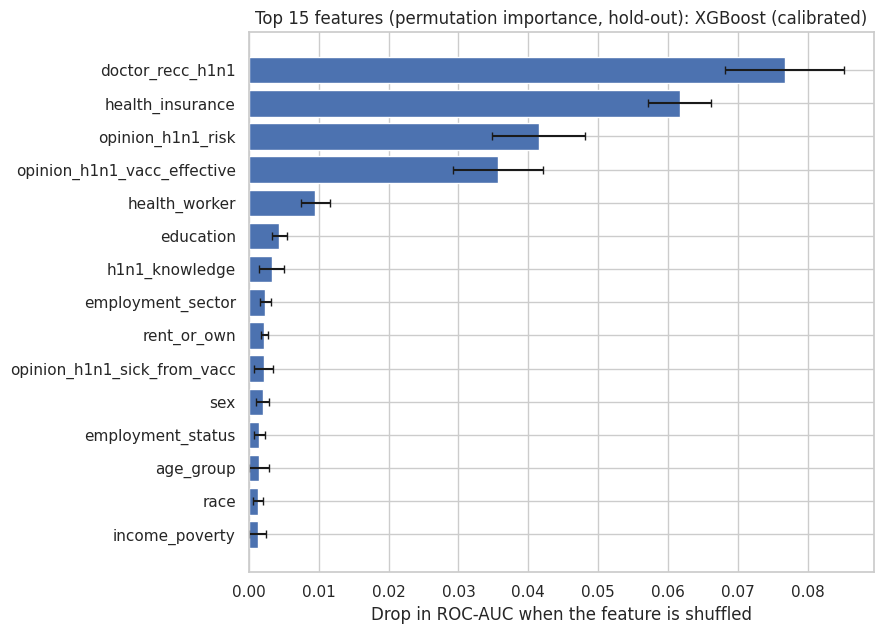

                             importance     std
doctor_recc_h1n1                 0.0767  0.0085
health_insurance                 0.0617  0.0045
opinion_h1n1_risk                0.0415  0.0067
opinion_h1n1_vacc_effective      0.0356  0.0064
health_worker                    0.0095  0.0021
education                        0.0043  0.0011
h1n1_knowledge                   0.0032  0.0018
employment_sector                0.0024  0.0008
rent_or_own                      0.0022  0.0005
opinion_h1n1_sick_from_vacc      0.0021  0.0014


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_hold, y_hold, scoring='roc_auc',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'importance': perm.importances_mean, 'std': perm.importances_std},
                   index=FEATURES).sort_values('importance', ascending=False)

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top['importance'], xerr=top['std'], color='#4C72B0', capsize=3)
ax.set_xlabel('Drop in ROC-AUC when the feature is shuffled')
ax.set_title(f'Top 15 features (permutation importance, hold-out): {best_key}')
plt.tight_layout()
plt.show()

print(imp.head(10).round(4).to_string())

## 12. Final model and submission

The selected model is refit on **all 4,756 labelled people** (development + hold-out), so it learns from as much data as possible. It then predicts each test respondent's probability of accepting, and the risk-aware rule (with the median AI parameters) decides who receives a dose.

The file follows the example format: `respondent_id`, `h1n1_vaccine` (1.0 = send a dose, 0.0 = don't).

In [ ]:
production_model = build_final_model(best_key).fit(X, y)

p_test = production_model.predict_proba(test[FEATURES])[:, 1]
risk_test = hosp_risk_unvaccinated(test)
send_test = (p_test >= risk_aware_threshold(risk_test)).astype(float)

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: send_test})

# Checks against the example submission format
example = pd.read_csv('dataset_B_example_submission.csv') if os.path.exists('dataset_B_example_submission.csv') else None
assert submission.shape == (len(test), 2)
assert submission[TARGET].isin([0.0, 1.0]).all()
if example is not None:
    assert submission[ID_COL].equals(example[ID_COL]), 'Row order differs from example'
    print('Format matches the example submission ✅')

submission.to_csv('submission_main.csv', index=False)
print(f'Doses to send: {int(send_test.sum())} of {len(test)} ({send_test.mean():.1%})')
print(f'Expected number who want a vaccine (sum of probabilities): {p_test.sum():.0f}')
submission.head()

Doses to send: 805 of 4749 (17.0%)
Expected number who want a vaccine (sum of probabilities): 1883


,respondent_id,h1n1_vaccine
0,4757,0.0
1,4758,0.0
2,4759,0.0
3,4760,0.0
4,4761,0.0


In [ ]:
# Download the submission file(s) (Colab only)
try:
    from google.colab import files
    to_download = ['submission_main.csv']
    if 'SCENARIO_BASES' in globals():      # add scenario files only if that cell was run
        to_download += [f'submission_{k}.csv' for k in SCENARIO_BASES]
    for f in to_download:
        if os.path.exists(f):
            files.download(f)
        else:
            print('Not found (cell not run yet):', f)
except ImportError:
    print('Not in Colab: files are saved in the working directory.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>